<a href="https://colab.research.google.com/github/apoorv19151/Toxic-Tweet-Classification/blob/main/notebooks/04_distilbert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install -q transformers datasets accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.8 MB/s eta 0:00:00


In [3]:
import random
import os
import numpy as np
import pandas as pd

from pathlib import Path

import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from torch.utils.data import Dataset

from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

import matplotlib.pyplot as plt

In [4]:
SEED = 42
MAX_LENGTH = 64

In [5]:
random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

In [6]:
print(torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

if torch.cuda.is_available():
  print(torch.cuda.get_device_name(0))

True
cuda
Tesla T4


In [7]:
!nvidia-smi

Mon Jul 20 19:52:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [8]:
project_dir = Path("/content/drive/MyDrive/sentiment_analysis")

df = pd.read_csv(project_dir / "tweets_transformer.csv")

df.head()

,sentiment,clean_text,tweet_length
0,not_cyberbullying,"In other words #katandandre, your food was cra...",9
1,not_cyberbullying,Why is #aussietv so white? #MKR #theblock #ImA...,14
2,not_cyberbullying,@XochitlSuckkks a classy whore? Or more red ve...,8
3,not_cyberbullying,"@Jason_Gio meh. :P thanks for the heads up, bu...",17
4,not_cyberbullying,@RudhoeEnglish This is an ISIS account pretend...,17


In [9]:
label2id = {
    "religion": 0,
    "age": 1,
    "ethnicity": 2,
    "gender": 3,
    "other_cyberbullying": 4,
    "not_cyberbullying": 5
}

id2label = {v: k for k, v in label2id.items()}

df["label"] = df["sentiment"].map(label2id)

df.head()

,sentiment,clean_text,tweet_length,label
0,not_cyberbullying,"In other words #katandandre, your food was cra...",9,5
1,not_cyberbullying,Why is #aussietv so white? #MKR #theblock #ImA...,14,5
2,not_cyberbullying,@XochitlSuckkks a classy whore? Or more red ve...,8,5
3,not_cyberbullying,"@Jason_Gio meh. :P thanks for the heads up, bu...",17,5
4,not_cyberbullying,@RudhoeEnglish This is an ISIS account pretend...,17,5


In [10]:
lengths = df["tweet_length"]

print(lengths.describe())

print(f"95th percentile: {lengths.quantile(0.95)}")
print(f"99th percentile: {lengths.quantile(0.99)}")
print(f"99.9th percentile: {lengths.quantile(0.999)}")

count    47564.000000
mean        23.810992
std         16.063872
min          0.000000
25%         12.000000
50%         20.000000
75%         33.000000
max        755.000000
Name: tweet_length, dtype: float64
95th percentile: 52.0
99th percentile: 57.0
99.9th percentile: 62.0


In [11]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["sentiment"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["sentiment"],
    random_state=SEED
)

In [12]:
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

print()
print(f"Training set distribution:\n{train_df['sentiment'].value_counts()}\n")
print(f"Validation set distribution:\n{val_df['sentiment'].value_counts()}\n")
print(f"Test set distribution:\n{test_df['sentiment'].value_counts()}\n")

Training set size: 38051
Validation set size: 4756
Test set size: 4757

Training set distribution:
sentiment
religion               6397
age                    6394
ethnicity              6366
gender                 6354
not_cyberbullying      6337
other_cyberbullying    6203
Name: count, dtype: int64

Validation set distribution:
sentiment
religion               800
age                    799
ethnicity              796
gender                 794
not_cyberbullying      792
other_cyberbullying    775
Name: count, dtype: int64

Test set distribution:
sentiment
religion               800
age                    799
ethnicity              796
gender                 794
not_cyberbullying      792
other_cyberbullying    776
Name: count, dtype: int64



In [13]:
tokenizer = DistilBertTokenizerFast.from_pretrained(
    "distilbert-base-uncased"
)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [14]:
train_encodings = tokenizer(
    train_df["clean_text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

val_encodings = tokenizer(
    val_df["clean_text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

test_encodings = tokenizer(
    test_df["clean_text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

In [15]:
sample = 0

print("Original Tweet:")
print(train_df.loc[sample, "clean_text"])

print("Input IDs:")
print(train_encodings["input_ids"][sample])

print("Attention Mask:")
print(train_encodings["attention_mask"][sample])

Original Tweet:
And before I hear anyone defending AGG - don't. It's a shit sub where I had to fight to get a thread taken down by one of my stalkers.
Input IDs:
[101, 1998, 2077, 1045, 2963, 3087, 6984, 12943, 2290, 1011, 2123, 1005, 1056, 1012, 2009, 1005, 1055, 1037, 4485, 4942, 2073, 1045, 2018, 2000, 2954, 2000, 2131, 1037, 11689, 2579, 2091, 2011, 2028, 1997, 2026, 23883, 2015, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Attention Mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [16]:
class TweetDataset(Dataset):
  def __init__(self, encodings, labels):
    self.encodings = encodings
    self.labels = labels

  def __len__(self):
    return len(self.labels)

  def __getitem__(self, idx):
    item = {
        key: torch.tensor(value[idx])
        for key, value in self.encodings.items()
    }

    item["labels"] = torch.tensor(self.labels[idx])

    return item

train_dataset = TweetDataset(
    train_encodings,
    train_df["label"].tolist()
)

val_dataset = TweetDataset(
    val_encodings,
    val_df["label"].tolist()
)

test_dataset = TweetDataset(
    test_encodings,
    test_df["label"].tolist()
)

In [17]:
model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=6,
    id2label=id2label,
    label2id=label2id
)

model.to(device)

print(model)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [18]:
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable parameters: {num_params:,}")

Trainable parameters: 66,958,086


In [19]:
def compute_metrics(eval_pred):
  logits, labels = eval_pred

  predictions = np.argmax(logits, axis=-1)

  precision, recall, f1, _ = precision_recall_fscore_support(
      labels,
      predictions,
      average="macro"
  )

  accuracy = accuracy_score(labels, predictions)

  return {
      "accuracy": accuracy,
      "macro_f1": f1,
      "precision": precision,
      "recall": recall
  }

training_args = TrainingArguments(
    output_dir="results",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    num_train_epochs=3,

    weight_decay=0.01,

    load_best_model_at_end=True,

    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,

    logging_steps=100,

    save_total_limit=1,

    report_to="none",

    fp16=True,

    seed=SEED
)

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall
1,0.347899,0.360347,0.858705,0.856795,0.863221,0.858118
2,0.277670,0.337927,0.868167,0.867168,0.867347,0.867212
3,0.226917,0.359021,0.868587,0.867400,0.868688,0.867777


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=7137, training_loss=0.3253687067126733, metrics={'train_runtime': 333.3405, 'train_samples_per_second': 342.452, 'train_steps_per_second': 21.411, 'total_flos': 1890328705544448.0, 'train_loss': 0.3253687067126733, 'epoch': 3.0})

In [20]:
history = pd.DataFrame(trainer.state.log_history)

history.head()

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_macro_f1,eval_precision,eval_recall,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.276731,4.873569,0.000020,0.042034,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.642137,5.620196,0.000019,0.084069,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.500431,2.193950,0.000019,0.126103,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.499301,8.588096,0.000019,0.168138,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.443653,4.575280,0.000019,0.210172,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


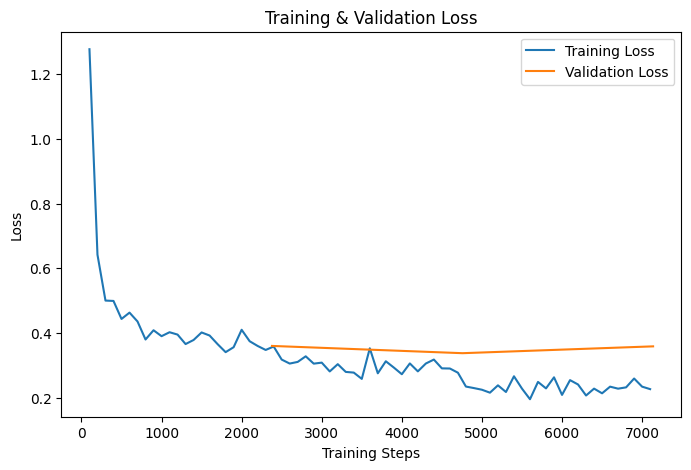

In [21]:
train_loss = history[history["loss"].notna()]
eval_loss = history[history["eval_loss"].notna()]

plt.figure(figsize=(8,5))

plt.plot(train_loss["step"], train_loss["loss"], label="Training Loss")
plt.plot(eval_loss["step"], eval_loss["eval_loss"], label="Validation Loss")

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")

plt.legend()

plt.show()

In [22]:
test_results = trainer.evaluate(test_dataset)

print(test_results)

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Precision,Recall
0.226917,0.353844,3,0.869245,0.867633,0.869003,0.868459


{'eval_loss': 0.35384365916252136, 'eval_accuracy': 0.8692453226823629, 'eval_macro_f1': 0.8676333475954251, 'eval_precision': 0.8690031135400272, 'eval_recall': 0.8684594857096132}


In [23]:
predictions = trainer.predict(test_dataset)

y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

report = classification_report(
    y_true,
    y_pred,
    target_names=id2label.values(),
    digits=3,
    output_dict=True
)

print(report)

{'religion': {'precision': 0.9616336633663366, 'recall': 0.97125, 'f1-score': 0.9664179104477612, 'support': 800.0}, 'age': {'precision': 0.9823899371069182, 'recall': 0.9774718397997497, 'f1-score': 0.9799247176913425, 'support': 799.0}, 'ethnicity': {'precision': 0.989769820971867, 'recall': 0.9723618090452262, 'f1-score': 0.9809885931558935, 'support': 796.0}, 'gender': {'precision': 0.8983890954151177, 'recall': 0.9130982367758187, 'f1-score': 0.905683947532792, 'support': 794.0}, 'other_cyberbullying': {'precision': 0.674233825198638, 'recall': 0.7654639175257731, 'f1-score': 0.7169583584791792, 'support': 776.0}, 'not_cyberbullying': {'precision': 0.7076023391812866, 'recall': 0.6111111111111112, 'f1-score': 0.6558265582655827, 'support': 792.0}, 'accuracy': 0.8692453226823629, 'macro avg': {'precision': 0.8690031135400272, 'recall': 0.8684594857096132, 'f1-score': 0.8676333475954251, 'support': 4757.0}, 'weighted avg': {'precision': 0.8700947468321271, 'recall': 0.86924532268236

In [24]:
report = classification_report(
    y_true,
    y_pred,
    target_names=id2label.values(),
    digits=3,
    output_dict=False
)

print(report)

                     precision    recall  f1-score   support

           religion      0.962     0.971     0.966       800
                age      0.982     0.977     0.980       799
          ethnicity      0.990     0.972     0.981       796
             gender      0.898     0.913     0.906       794
other_cyberbullying      0.674     0.765     0.717       776
  not_cyberbullying      0.708     0.611     0.656       792

           accuracy                          0.869      4757
          macro avg      0.869     0.868     0.868      4757
       weighted avg      0.870     0.869     0.869      4757



<Figure size 800x800 with 0 Axes>

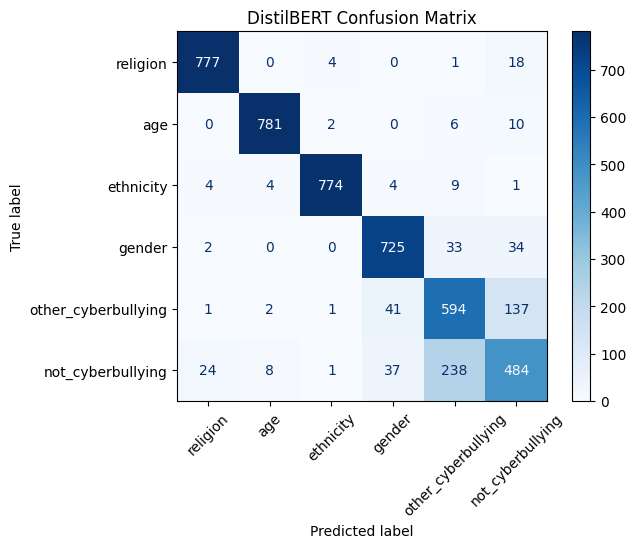

In [25]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(label2id.keys())
)

plt.figure(figsize=(8, 8))

disp.plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("DistilBERT Confusion Matrix")
plt.show()

In [26]:
model.save_pretrained(project_dir / "models" / "distilbert")
tokenizer.save_pretrained(project_dir / "models" / "distilbert")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/sentiment_analysis/models/distilbert/tokenizer_config.json',
 '/content/drive/MyDrive/sentiment_analysis/models/distilbert/tokenizer.json')